# Results: predicting Reddit post success

Figures and tables for the report. This notebook does not train the expensive models. It reads:

- the extract in `data/textonly/` (`extract_subreddits.py`)
- cached dadjokes data and predictions in `data/models/` (`python run_dadjokes_models.py`, ~35 min with fine-tuning)
- `results/per_subreddit.csv` (one logistic regression per subreddit vs. the pooled model of `textonly_baselines.ipynb`)

**Setup.** A post is a *success* if its engagement, ln(1 + score) + ln(1 + comments), is in the top 10% of its
subreddit and quarter. Train: before 2024. Validation: 2024. Test: 2025-01 to 2026-02. All numbers below are on
the test set. Models predict log engagement; the main metric is the **top-10% hit rate**: of the posts a model
ranks in its top 10%, the share that are successes (chance = 10%).

In [1]:
import pickle

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from sklearn.metrics import average_precision_score, precision_recall_curve

import dadjokes_models as dm
import textonly_baselines as tb
import textonly_data as td

td.set_style()
pd.set_option("display.precision", 3)
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
DIVERGING = LinearSegmentedColormap.from_list("div", [td.ORANGE, "#f0efec", td.BLUE])
GRAY = "#b9b8b3"

## 1. Data

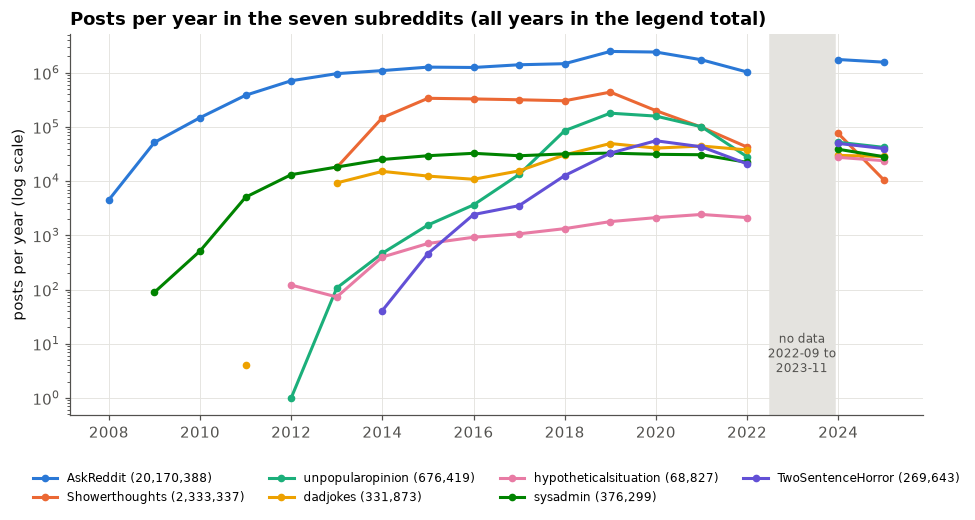

,posts
subreddit,
AskReddit,20170388
Showerthoughts,2333337
unpopularopinion,676419
sysadmin,376299
dadjokes,331873
TwoSentenceHorror,269643
hypotheticalsituation,68827


In [2]:
counts = duckdb.sql(f"""
SELECT subreddit, year(created_at) AS year, count(*) AS posts
FROM read_parquet('{td.SOURCES["local"]}') GROUP BY ALL
""").df()
totals = counts.groupby("subreddit").posts.sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 4.5))
for sub in td.SUBREDDITS:
    # 2023 has only December and 2026 only two months, so they are left out (the line breaks at the gap)
    d = counts[counts.subreddit == sub].set_index("year").posts.reindex(range(2008, 2026))
    d[2023] = np.nan
    ax.plot(d.index, d, color=td.COLORS[sub], marker="o", markersize=4, label=f"{sub} ({totals[sub]:,})")
ax.axvspan(2022.5, 2023.92, color="#e4e3df", zorder=0)
ax.text(2023.2, 3, "no data\n2022-09 to\n2023-11", ha="center", fontsize=8, color=td.MUTED)
ax.set_xticks(range(2008, 2026, 2))
ax.set_yscale("log")
ax.set_ylabel("posts per year (log scale)")
ax.set_title("Posts per year in the seven subreddits (all years in the legend total)")
ax.legend(fontsize=8, ncols=4, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.show()
totals.to_frame("posts")

## 2. Timing in r/dadjokes

dadjokes is the subreddit we model in depth: its score distribution is stable over the years (median score 7–8)
and it has the strongest timing pattern. Success rates below are divided by the overall rate (1.0 = average).

{'train': 266053, 'val': 29760, 'test': 32826}


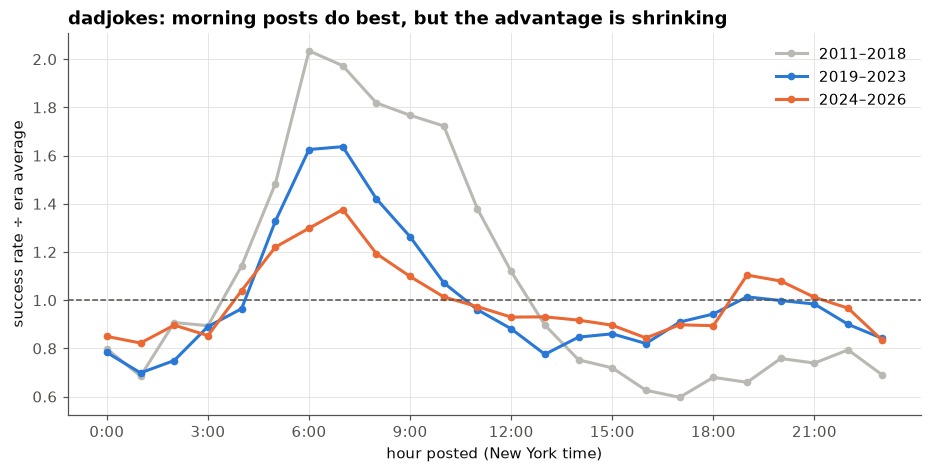

,6–9am lift
era,
2011–2018,1.927
2019–2023,1.549
2024–2026,1.285


In [3]:
data = dm.load(dm.Config())
dj = pd.concat([data.train, data.val, data.test])
dj["era"] = pd.cut(dj.created_at.dt.year, [0, 2018, 2023, 2100], labels=["2011–2018", "2019–2023", "2024–2026"])

hourly = dj.groupby(["era", "local_hour"], observed=True).label.mean().unstack(0)
hourly = hourly / dj.groupby("era", observed=True).label.mean()

fig, ax = plt.subplots(figsize=(10, 4.5))
for era, color in zip(hourly.columns, [GRAY, td.BLUE, td.ORANGE]):
    ax.plot(hourly.index, hourly[era], color=color, marker="o", markersize=4, label=era)
ax.axhline(1, color=td.MUTED, lw=1, ls="--")
ax.set_xticks(range(0, 24, 3), [f"{h}:00" for h in range(0, 24, 3)])
ax.set_xlabel("hour posted (New York time)")
ax.set_ylabel("success rate ÷ era average")
ax.set_title("dadjokes: morning posts do best, but the advantage is shrinking")
ax.legend(frameon=False, loc="upper right")
plt.show()

morning = dj[dj.local_hour.between(6, 8)].groupby("era", observed=True).label.mean() / dj.groupby("era", observed=True).label.mean()
morning.rename("6–9am lift").to_frame()

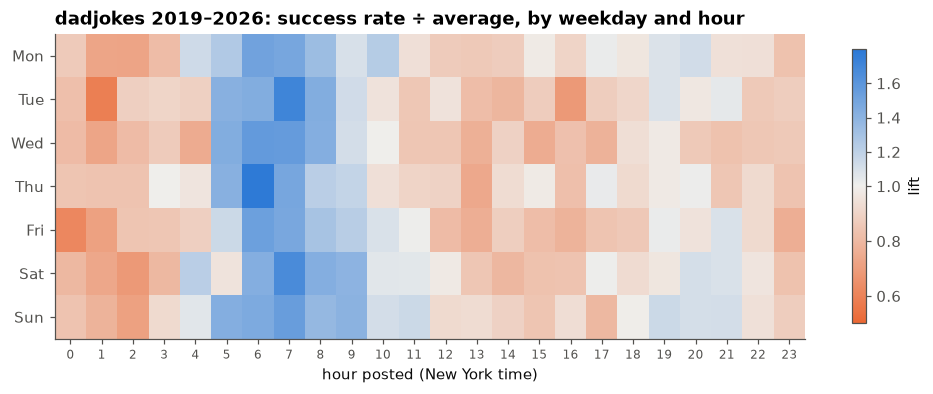

local_hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Mon,0.87,0.73,0.73,0.81,1.14,1.26,1.51,1.48,1.33,1.09,...,0.87,0.98,0.90,1.02,0.97,1.09,1.12,0.95,0.94,0.83
Tue,0.83,0.59,0.89,0.91,0.89,1.42,1.44,1.71,1.44,1.13,...,0.79,0.87,0.69,0.88,0.91,1.09,0.97,1.04,0.86,0.88
Wed,0.81,0.73,0.81,0.87,0.75,1.44,1.56,1.56,1.44,1.11,...,0.89,0.76,0.83,0.78,0.94,0.98,0.86,0.83,0.85,0.86
Thu,0.84,0.84,0.84,1.00,0.96,1.42,1.78,1.48,1.22,1.18,...,0.93,0.98,0.83,1.03,0.92,0.98,1.02,0.85,0.92,0.84
Fri,0.62,0.71,0.85,0.85,0.89,1.15,1.53,1.48,1.29,1.22,...,0.88,0.82,0.78,0.84,0.86,1.02,0.96,1.09,0.92,0.76
Sat,0.80,0.73,0.69,0.80,1.22,0.96,1.44,1.66,1.43,1.40,...,0.80,0.83,0.84,1.01,0.93,0.97,1.11,1.09,0.96,0.83
Sun,0.84,0.78,0.71,0.92,1.06,1.43,1.46,1.55,1.36,1.40,...,0.89,0.85,0.94,0.80,0.99,1.15,1.11,1.11,0.95,0.88


In [4]:
recent = dj[dj.created_at.dt.year >= 2019]
cells = recent.groupby(["local_dow", "local_hour"]).label.agg(["mean", "size"])
lift = (cells["mean"] / recent.label.mean()).unstack()
lift[cells["size"].unstack() < 30] = np.nan

fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(lift.to_numpy(), cmap=DIVERGING, norm=TwoSlopeNorm(vmin=0.5, vcenter=1, vmax=1.8), aspect="auto")
ax.set_xticks(range(24), [str(h) for h in range(24)], fontsize=8)
ax.set_yticks(range(7), DAYS)
ax.set_xlabel("hour posted (New York time)")
ax.grid(False)
ax.set_title("dadjokes 2019–2026: success rate ÷ average, by weekday and hour")
fig.colorbar(im, ax=ax, label="lift", shrink=0.9)
plt.show()
lift.round(2).set_axis(DAYS)

## 3. One model per subreddit beats one pooled model

Logistic regression with the same features (TF-IDF text, timing, structure, history), trained either on all seven
subreddits together (with the subreddit as a feature) or on one subreddit only.

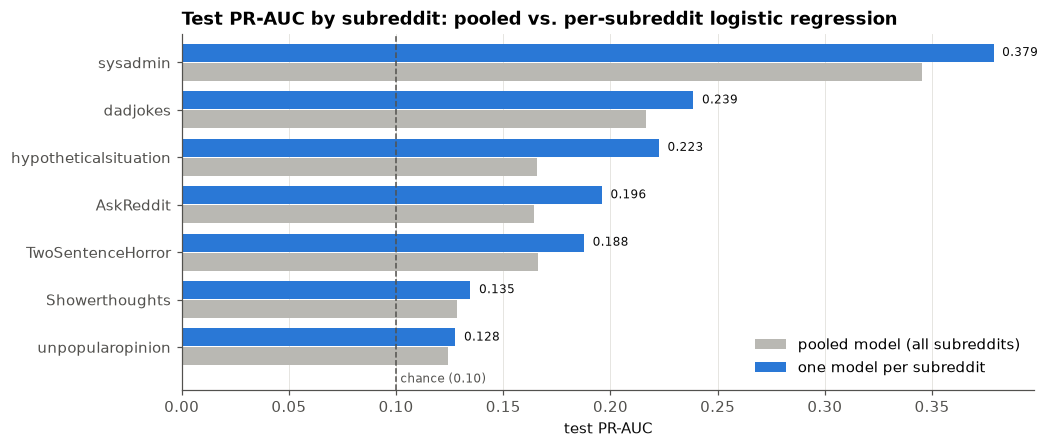

,pooled PR-AUC,own PR-AUC,own top-10% hit
subreddit,,,
sysadmin,0.345,0.379,0.411
dadjokes,0.217,0.239,0.278
hypotheticalsituation,0.166,0.223,0.270
AskReddit,0.165,0.196,0.241
TwoSentenceHorror,0.166,0.188,0.222
Showerthoughts,0.128,0.135,0.154
unpopularopinion,0.124,0.128,0.145


In [5]:
ps = pd.read_csv("results/per_subreddit.csv")
own = ps[ps.model == "all"].set_index("subreddit")
own = own.sort_values("test_pr")

fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(own))
ax.barh(y - 0.2, own.pooled_test_pr, height=0.38, color=GRAY, label="pooled model (all subreddits)")
ax.barh(y + 0.2, own.test_pr, height=0.38, color=td.BLUE, label="one model per subreddit")
for yi, v in zip(y, own.test_pr):
    ax.text(v + 0.004, yi + 0.2, f"{v:.3f}", va="center", fontsize=8, color=td.INK)
ax.axvline(0.10, color=td.MUTED, lw=1, ls="--")
ax.text(0.102, -0.75, "chance (0.10)", fontsize=8, color=td.MUTED)
ax.set_ylim(-0.9, len(own) - 0.4)
ax.set_yticks(y, own.index)
ax.set_xlabel("test PR-AUC")
ax.set_title("Test PR-AUC by subreddit: pooled vs. per-subreddit logistic regression")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
plt.show()
own[["pooled_test_pr", "test_pr", "prec_top10"]].rename(columns={
    "pooled_test_pr": "pooled PR-AUC", "test_pr": "own PR-AUC", "prec_top10": "own top-10% hit"})[::-1]

## 4. Models for r/dadjokes

All models predict log engagement from features known at posting time. *Metadata* = timing (hour, weekday,
month, posts in the previous hour/day), structure (lengths, question mark, number, all caps, link, author flair)
and history (author's earlier posts, repost). The timing-only model is ridge regression on the timing features.

In [6]:
preds = pickle.load(open(dm.CACHE_DIR / "predictions.pkl", "rb"))

# Timing only: cheap, so it is fitted here
tb.GROUPS = {k: v for k, v in tb.GROUPS.items() if k != "subreddit"}
f = tb.build_features(data, text=False)
p_val, p_test, _ = dm.fit_ridge(data, {s: f.combine(["timing"], s) for s in dm.SPLITS})
preds = {"ridge (timing only)": {"val": p_val, "test": p_test}} | preds

rows = {name: dm.scores(data.test, p["test"]) for name, p in preds.items()}
table = pd.DataFrame(rows).T.sort_values("top10_hit")
table.columns = ["Spearman", "PR-AUC", "top-10% hit rate"]
table[::-1]

{'timing': 44, 'structure': 9, 'history': 2}


  ridge alpha=0.3


,Spearman,PR-AUC,top-10% hit rate
blend: fine-tuned MiniLM (text only) + hgb (meta only),0.367,0.274,0.318
fine-tuned MiniLM (text only),0.356,0.266,0.314
blend: fine-tuned MiniLM (text only) + ridge (tf-idf + meta),0.374,0.272,0.312
ridge (tf-idf + meta),0.313,0.234,0.283
"hgb (meta + tf-idf + embedding ridges, stacked)",0.322,0.237,0.281
ridge (embeddings + tf-idf + meta),0.337,0.240,0.281
"hgb (meta + tf-idf ridge, stacked)",0.306,0.230,0.275
ridge (tf-idf only),0.277,0.212,0.252
ridge (embeddings only),0.210,0.169,0.201
hgb (meta only),0.185,0.164,0.200


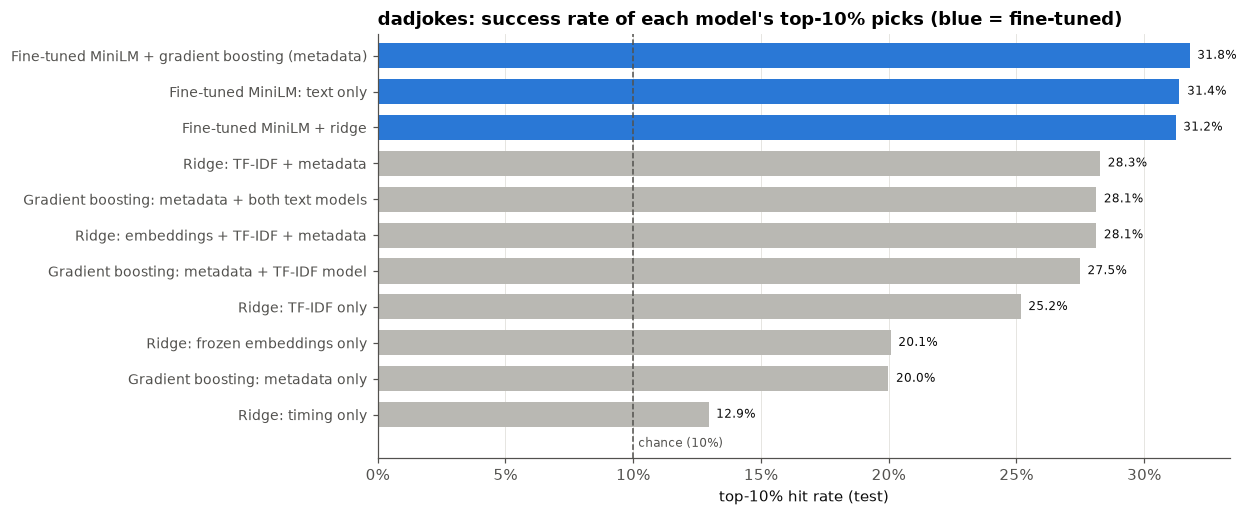

In [7]:
BEST = "blend: fine-tuned MiniLM (text only) + hgb (meta only)"
NAMES = {
    "ridge (timing only)": "Ridge: timing only",
    "hgb (meta only)": "Gradient boosting: metadata only",
    "ridge (embeddings only)": "Ridge: frozen embeddings only",
    "ridge (tf-idf only)": "Ridge: TF-IDF only",
    "hgb (meta + tf-idf ridge, stacked)": "Gradient boosting: metadata + TF-IDF model",
    "ridge (embeddings + tf-idf + meta)": "Ridge: embeddings + TF-IDF + metadata",
    "hgb (meta + tf-idf + embedding ridges, stacked)": "Gradient boosting: metadata + both text models",
    "ridge (tf-idf + meta)": "Ridge: TF-IDF + metadata",
    "blend: fine-tuned MiniLM (text only) + ridge (tf-idf + meta)": "Fine-tuned MiniLM + ridge",
    "fine-tuned MiniLM (text only)": "Fine-tuned MiniLM: text only",
    BEST: "Fine-tuned MiniLM + gradient boosting (metadata)",
}
t = table.copy()
t.index = [NAMES[i] for i in t.index]
colors = [td.BLUE if "Fine-tuned" in n else GRAY for n in t.index]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(range(len(t)), t["top-10% hit rate"], color=colors, height=0.7)
for i, v in enumerate(t["top-10% hit rate"]):
    ax.text(v + 0.003, i, f"{v:.1%}", va="center", fontsize=8, color=td.INK)
ax.axvline(0.10, color=td.MUTED, lw=1, ls="--")
ax.text(0.102, -0.9, "chance (10%)", fontsize=8, color=td.MUTED)
ax.set_yticks(range(len(t)), t.index, fontsize=9)
ax.set_ylim(-1.2, len(t) - 0.4)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("top-10% hit rate (test)")
ax.set_title("dadjokes: success rate of each model's top-10% picks (blue = fine-tuned)")
ax.grid(axis="y", visible=False)
plt.show()

### Hit rate by how selective the model is

If we only post the jokes the model likes best, how often do they succeed? The x-axis is the share of test posts
the model selects, ranked by its prediction.

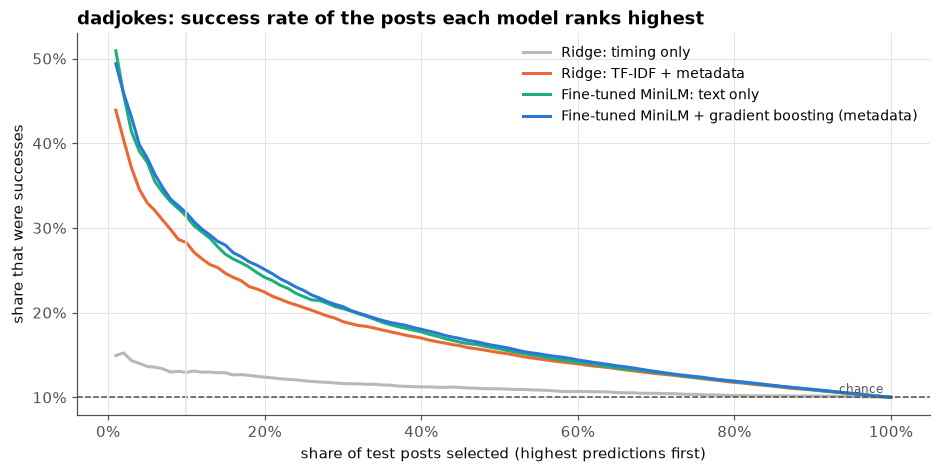

In [8]:
SHOW = {"ridge (timing only)": GRAY, "ridge (tf-idf + meta)": td.ORANGE,
        "fine-tuned MiniLM (text only)": td.AQUA, BEST: td.BLUE}
y = data.test.label.to_numpy()
share = np.linspace(0.01, 1, 100)

fig, ax = plt.subplots(figsize=(10, 4.5))
for name, color in SHOW.items():
    order = np.argsort(-preds[name]["test"])
    hit = [y[order[: max(1, int(s * len(y)))]].mean() for s in share]
    ax.plot(share, hit, color=color, label=NAMES[name])
ax.axhline(y.mean(), color=td.MUTED, lw=1, ls="--")
ax.text(0.99, y.mean() + 0.005, "chance", ha="right", fontsize=8, color=td.MUTED)
ax.axvline(0.10, color="#e4e3df", lw=1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("share of test posts selected (highest predictions first)")
ax.set_ylabel("share that were successes")
ax.set_title("dadjokes: success rate of the posts each model ranks highest")
ax.legend(frameon=False, fontsize=9)
plt.show()

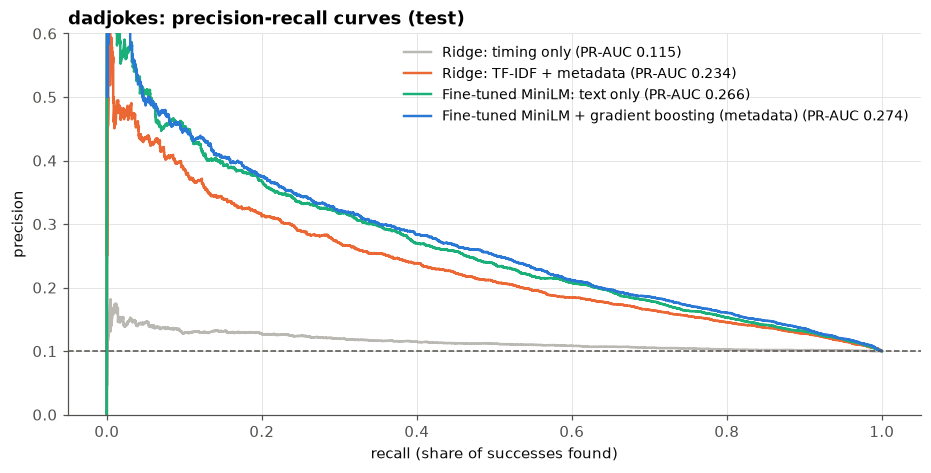

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for name, color in SHOW.items():
    prec, rec, _ = precision_recall_curve(y, preds[name]["test"])
    ap = average_precision_score(y, preds[name]["test"])
    ax.plot(rec, prec, color=color, lw=1.6, label=f"{NAMES[name]} (PR-AUC {ap:.3f})")
ax.axhline(y.mean(), color=td.MUTED, lw=1, ls="--")
ax.set_xlabel("recall (share of successes found)")
ax.set_ylabel("precision")
ax.set_ylim(0, 0.6)
ax.set_title("dadjokes: precision-recall curves (test)")
ax.legend(frameon=False, fontsize=9)
plt.show()

### Success rate by predicted decile (best model)

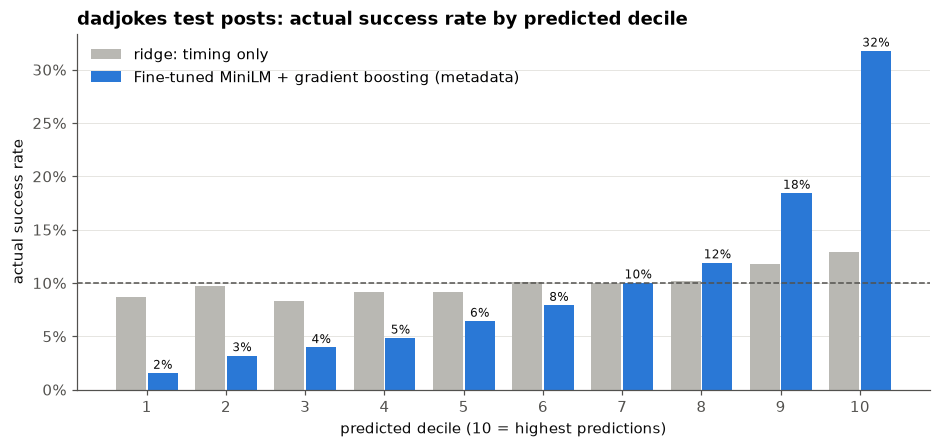

,1,2,3,4,5,6,7,8,9,10
best model,0.016,0.032,0.040,0.048,0.064,0.079,0.1,0.119,0.184,0.318
timing only,0.087,0.097,0.083,0.092,0.091,0.101,0.1,0.101,0.118,0.129


In [10]:
d = data.test.assign(p=preds[BEST]["test"], p_time=preds["ridge (timing only)"]["test"])
d["decile"] = pd.qcut(d.p.rank(method="first"), 10, labels=range(1, 11))
d["decile_time"] = pd.qcut(d.p_time.rank(method="first"), 10, labels=range(1, 11))
by = pd.DataFrame({"best model": d.groupby("decile", observed=True).label.mean(),
                   "timing only": d.groupby("decile_time", observed=True).label.mean()})

fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(1, 11)
ax.bar(x - 0.2, by["timing only"], width=0.38, color=GRAY, label="ridge: timing only")
ax.bar(x + 0.2, by["best model"], width=0.38, color=td.BLUE, label=NAMES[BEST])
for xi, v in zip(x, by["best model"]):
    ax.text(xi + 0.2, v + 0.004, f"{v:.0%}", ha="center", fontsize=8, color=td.INK)
ax.axhline(y.mean(), color=td.MUTED, lw=1, ls="--")
ax.set_xticks(x, [f"{i}" for i in x])
ax.set_xlabel("predicted decile (10 = highest predictions)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("actual success rate")
ax.set_title("dadjokes test posts: actual success rate by predicted decile")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)
plt.show()
by.T

## 5. What the text model learned

Ridge regression on TF-IDF only (title + body before any edit note), refit here on terms that appear in at least
200 training posts, so the weights show common patterns rather than single jokes. Positive weights predict higher
engagement.

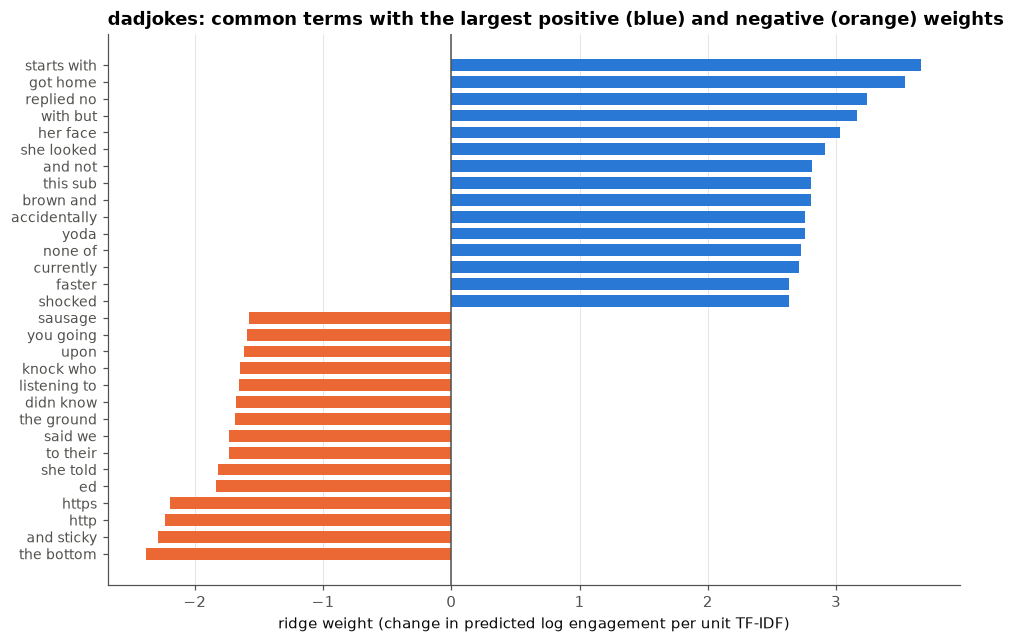

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=200, max_features=50_000, sublinear_tf=True,
                        strip_accents="unicode", dtype=np.float32)
Xtr = tfidf.fit_transform(dm.text_of(data.train))
ridge = Ridge(alpha=3).fit(Xtr, data.train.metric)
coef = pd.Series(ridge.coef_, tfidf.get_feature_names_out())
top = pd.concat([coef.nsmallest(15), coef.nlargest(15)[::-1]])

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(range(len(top)), top, color=[td.BLUE if v > 0 else td.ORANGE for v in top], height=0.7)
ax.set_yticks(range(len(top)), top.index, fontsize=9)
ax.axvline(0, color=td.MUTED, lw=1)
ax.set_xlabel("ridge weight (change in predicted log engagement per unit TF-IDF)")
ax.set_title("dadjokes: common terms with the largest positive (blue) and negative (orange) weights")
ax.grid(axis="y", visible=False)
plt.show()

## 6. Summary

- **Content beats timing.** Morning posts in dadjokes succeed up to ~1.8× as often as average, but the effect is
  fading (6–9am lift 1.81× before 2019, 1.29× since 2024) and a timing-only model is barely above chance.
- **One model per subreddit** beats a pooled model in all seven subreddits.
- **Fine-tuning a small transformer is the first model that clearly beats word counts**: its top-10% picks are
  successes 31% of the time, 32% when blended with metadata (3.2× chance), vs. 28% for ridge on TF-IDF.
  Frozen embeddings and gradient boosting do not beat ridge.